# Comparing float32 and float64 wave simulations

This notebook compares accuracy of NFT wave simulations using `float32` and
`float64` where the latter is used as a reference. Each solver computes the same number of eigenmodes using the selected dtype. We compare
the resulting activity for Fourier, ODE, and FEM methods against the `float64` run, using the
same external input for both precisions. The inputs are (i) a local stimuluation and (ii) global
white noise. Supplying the same input explicitly avoids comparing different random-number streams
from dtype-specific noise generation.

In [1]:
import tracemalloc

import matplotlib.pyplot as plt
import numpy as np

from neuromodes import EigenSolver
from neuromodes.io import fetch_example_surf
from neuromodes.stats import cdistw, meanw

In [2]:
# Load a 4k surface and configure matching solvers
surf, medmask = fetch_example_surf(res='4k')
solver64 = EigenSolver(surf, medmask, dtype=np.float64)
solver32 = EigenSolver(surf, medmask, dtype=np.float32)

In [3]:
# Parameters
n_modes = 500
r = 25  # For visualisation purposes
gamma = 116
nt = 500
dt = 1e-4
seed = 0

# Solve in each dtype with the same initialization seed
solver64.solve(n_modes=n_modes, seed=seed)
solver32.solve(n_modes=n_modes, seed=seed)
print(f"{solver64}\n\n{solver32}")

EigenSolver
-----------
Surface mesh: 3619 vertices (383 others masked out), 7144 triangles
Mass matrix: consistent
Stiffness matrix: homogeneous
Eigenmodes and eigenvalues: 500 computed

EigenSolver
-----------
Surface mesh: 3619 vertices (383 others masked out), 7144 triangles
Mass matrix: consistent
Stiffness matrix: homogeneous
Eigenmodes and eigenvalues: 500 computed


In [4]:
def sparse_nbytes(matrix):
    return matrix.data.nbytes + matrix.indices.nbytes + matrix.indptr.nbytes


for label, solver in (('float64', solver64), ('float32', solver32)):
    mode_bytes = solver.emodes.nbytes + solver.evals.nbytes
    mass_bytes = sparse_nbytes(solver.mass)
    stiffness_bytes = sparse_nbytes(solver.stiffness)
    print(
        f'{label}: emodes/evals={mode_bytes / 2**20:.1f} MiB, '
        f'mass={mass_bytes / 2**20:.1f} MiB, '
        f'stiffness={stiffness_bytes / 2**20:.1f} MiB'
    )
    print(
        f'  dtypes: emodes={solver.emodes.dtype}, evals={solver.evals.dtype}, '
        f'mass={solver.mass.dtype}, stiffness={solver.stiffness.dtype}'
    )

float64: emodes/evals=13.8 MiB, mass=0.3 MiB, stiffness=0.3 MiB
  dtypes: emodes=float64, evals=float64, mass=float64, stiffness=float64
float32: emodes/evals=6.9 MiB, mass=0.2 MiB, stiffness=0.2 MiB
  dtypes: emodes=float32, evals=float32, mass=float32, stiffness=float32


## Define shared external inputs

In [5]:
# Define an arbitrary ROI and a step input
y_coords = solver64.geometry.v[:, 1]
roi = np.where(y_coords < np.percentile(y_coords, 5))[0]
local_input = np.zeros((solver64.n_verts, nt), dtype=np.float64)
local_input[roi, :10] = 1.0

# Generate one float64 white-noise input and pass this same array to both solvers
rng = np.random.default_rng(seed)
noise_input = rng.standard_normal((solver64.n_verts, nt))

inputs = {
    'Local stimulation input': local_input,
    'Global white noise input': noise_input
}

## Compare float32 results with the float64 reference

Relative RMSE is computed per time point using the mass-weighted mean squared error, normalized
by the float64 signal's mass-weighted mean square. Correlation is also mass-weighted and computed
between matching time points. `speed_limits=None` suppresses wave-speed warnings so the notebook
focuses on numerical differences.

In [6]:
methods = ('fourier', 'ode', 'fem')
results = {}

for input_name, ext_input in inputs.items():
    for method in methods:
        print(f"{input_name}, {method}\n{'-' * 80}")
        tracemalloc.start()
        reference = solver64.sim_nft_waves(
            method=method,
            ext_input=ext_input,
            r=r,
            gamma=gamma,
            dt=dt,
        )
        traced_memory64 = tracemalloc.get_traced_memory()
        tracemalloc.stop()

        tracemalloc.start()
        candidate = solver32.sim_nft_waves(
            method=method,
            ext_input=ext_input,
            r=r,
            gamma=gamma,
            dt=dt,
        )
        traced_memory32 = tracemalloc.get_traced_memory()
        print(f'Peak memory usage: float64={traced_memory64[1] / 2**20:.1f} MiB, '
              f'float32={traced_memory32[1] / 2**20:.1f} MiB')
        tracemalloc.stop()

        mse = meanw((reference - candidate) ** 2, solver64.mass)
        reference_mse = meanw(reference ** 2, solver64.mass)
        relative_rmse = 100 * np.sqrt(
            np.divide(
                mse,
                reference_mse,
                out=np.full_like(mse, np.nan, dtype=np.float64),
                where=reference_mse > 0
            )
        )
        correlation = 1 - np.diag(cdistw(reference, candidate, solver64.mass))
        results[(input_name, method)] = {
            'relative_rmse': relative_rmse,
            'correlation': correlation
        }

        print(
            f'Mean relative RMSE={np.nanmean(relative_rmse):.4g}%, '
            f'Mean correlation={np.nanmean(correlation):.8f}'
            f'\n'
        )
        del reference, candidate

Local stimulation input, fourier
--------------------------------------------------------------------------------
Peak memory usage: float64=40.4 MiB, float32=24.4 MiB
Mean relative RMSE=0.002636%, Mean correlation=0.99999289

Local stimulation input, ode
--------------------------------------------------------------------------------
Peak memory usage: float64=33.2 MiB, float32=30.7 MiB
Mean relative RMSE=0.002606%, Mean correlation=0.99999327

Local stimulation input, fem
--------------------------------------------------------------------------------
Peak memory usage: float64=157.5 MiB, float32=85.8 MiB
Mean relative RMSE=0.0002598%, Mean correlation=0.99999953

Global white noise input, fourier
--------------------------------------------------------------------------------
Peak memory usage: float64=33.2 MiB, float32=24.4 MiB
Mean relative RMSE=0.0007463%, Mean correlation=0.99999196

Global white noise input, ode
------------------------------------------------------------------

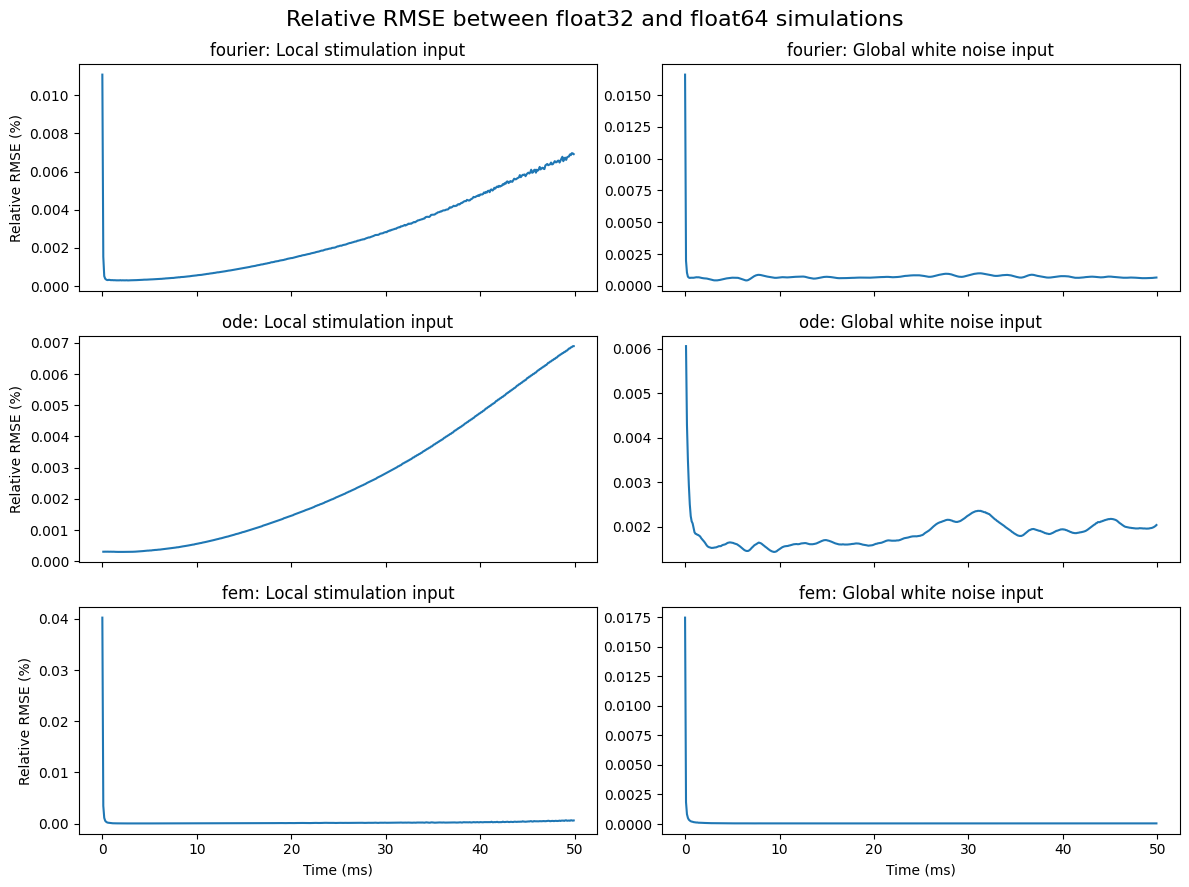

In [7]:
fig, axs = plt.subplots(len(methods), len(inputs), figsize=(12, 9), sharex=True)
for col, input_name in enumerate(inputs):
    for row, method in enumerate(methods):
        ax = axs[row, col]
        values = results[(input_name, method)]['relative_rmse']
        ax.plot(np.arange(nt) * dt * 1e3, values)
        ax.set_title(f'{method}: {input_name}')
        if col == 0:
            ax.set_ylabel('Relative RMSE (%)')
        if row == len(methods) - 1:
            ax.set_xlabel('Time (ms)')
fig.suptitle('Relative RMSE between float32 and float64 simulations', fontsize=16)
fig.tight_layout()
plt.show()

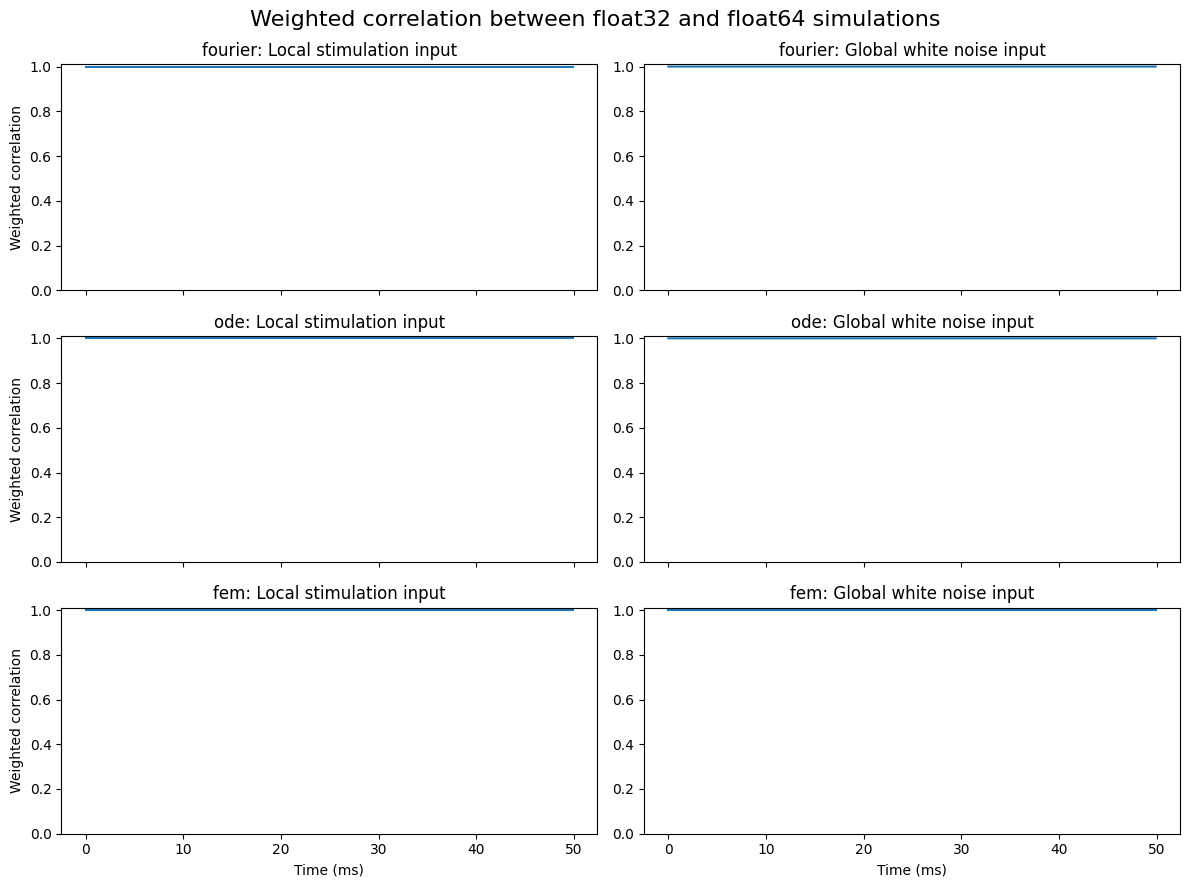

In [8]:
fig, axs = plt.subplots(len(methods), len(inputs), figsize=(12, 9), sharex=True)
for col, input_name in enumerate(inputs):
    for row, method in enumerate(methods):
        ax = axs[row, col]
        values = results[(input_name, method)]['correlation']
        ax.plot(np.arange(nt) * dt * 1e3, values)
        ax.set_ylim(0, 1.01)
        ax.set_title(f'{method}: {input_name}')
        if col == 0:
            ax.set_ylabel('Weighted correlation')
        if row == len(methods) - 1:
            ax.set_xlabel('Time (ms)')
fig.suptitle('Weighted correlation between float32 and float64 simulations', fontsize=16)
fig.tight_layout()
plt.show()